# Materi 1 — Mengatur Berbagai Alat AI untuk Membangun Solusi Kerja yang Utuh
**Pelatihan Gen AI Integrated Data Science**

---

## Tujuan pembelajaran
Setelah menyelesaikan notebook ini, peserta mampu:
1. Merangkai **LLM + Python (pandas) + visualisasi + manusia** menjadi satu alur kerja (*pipeline*) yang utuh.
2. Menerapkan **kontrak data JSON** antar langkah sehingga keluaran AI bisa diproses mesin.
3. Membuat **titik validasi** dan antrean **review manusia** (*human-in-the-loop*).
4. Membangun **router/agent sederhana** yang memilih *tool* yang tepat untuk sebuah pertanyaan.
5. Menyimpan **log audit** dan hasil pipeline ke file.

## Studi kasus
Tim *Customer Relations* menerima ratusan keluhan pelanggan dari dealer setiap bulan dalam bentuk teks bebas.
Kita akan membangun solusi yang otomatis **membaca → mengklasifikasi → memvalidasi → menganalisis → melaporkan** keluhan tersebut.

```
 [Teks keluhan] ──► (1) Ekstraksi LLM ──► (2) Validasi ──► (3) Review manusia
                                                                 │
 [Laporan & jawaban] ◄── (5) Ringkasan LLM ◄── (4) Analisis pandas ◄┘
                                 ▲
                 (6) Router/Agent: menjawab pertanyaan ad-hoc memakai tools
```

**Prinsip pembagian peran:** *AI memahami bahasa · Python menghitung · Manusia memutuskan.*

> Semua data di notebook ini adalah **data sintetis** untuk latihan, bukan data riil perusahaan.

## Langkah 0 — Menyiapkan library
Library yang dipakai:

| Library | Kegunaan di notebook ini |
|---|---|
| `numpy` | Membangkitkan angka acak yang dapat diulang (seed) untuk data sintetis. |
| `pandas` | Menyimpan dan mengolah tabel (DataFrame): filter, group by, pivot. |
| `matplotlib` | Membuat grafik (Pareto, tren mingguan). |
| `hashlib` | Membuat "sidik jari" teks agar simulator menghasilkan angka yang konsisten. |
| `requests` | Memanggil API LLM (hanya dipakai jika mode API diaktifkan). |

Jika memakai Google Colab / Jupyter baru, semua library ini umumnya sudah tersedia.

In [13]:
import hashlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.max_colwidth", 80)   # agar teks keluhan tidak terpotong terlalu pendek
plt.rcParams["figure.figsize"] = (9, 4)     # ukuran bawaan grafik (lebar, tinggi) dalam inci
print("pandas", pd.__version__, "| numpy", np.__version__)

pandas 3.0.3 | numpy 2.4.6


**Penjelasan kode**
- `import ... as pd/np/plt` — memberi alias pendek; ini konvensi umum di komunitas data science.
- `pd.set_option("display.max_colwidth", 80)` — mengatur tampilan tabel: kolom teks ditampilkan hingga 80 karakter.
- `plt.rcParams["figure.figsize"]` — *runtime configuration* matplotlib; semua grafik berikutnya memakai ukuran ini kecuali diubah.

## Langkah 1 — Membuat data keluhan pelanggan (sintetis)
Kita membuat 120 keluhan dari berbagai dealer, wilayah, dan model motor selama Juli–September 2026.
Setiap teks dibentuk dari **template kalimat** yang realistis, termasuk beberapa kalimat **ambigu** dan **positif** agar kasusnya menyerupai data nyata.

In [14]:
rng = np.random.default_rng(42)   # generator acak dengan seed 42 → hasil selalu sama setiap dijalankan

MODEL_MOTOR = ["BeAT", "Vario 125", "Scoopy", "PCX 160", "ADV 160", "CBR150R", "Genio"]
WILAYAH     = ["Jabodetabek", "Jawa Barat", "Jawa Tengah", "Jawa Timur", "Sumatera", "Kalimantan"]

# (template kalimat, bobot kemunculan) — {m} akan diganti nama model motor
TEMPLATE_KELUHAN = [
    ("Mesin {m} sering mati mendadak saat berhenti di lampu merah", 9),
    ("Tarikan {m} terasa berat setelah servis berkala", 7),
    ("Ada oli rembes di sekitar blok mesin {m}", 5),
    ("Aki {m} cepat habis padahal baru 6 bulan", 8),
    ("Lampu depan {m} redup di malam hari", 4),
    ("Starter elektrik {m} kadang tidak berfungsi pagi hari", 6),
    ("Rem depan {m} kurang pakem dan berbunyi decit", 7),
    ("Shock belakang {m} bocor, terasa mantul di jalan rusak", 4),
    ("Cat bodi {m} mengelupas di bagian spakbor", 3),
    ("Antrian servis di dealer lama sekali, lebih dari 3 jam", 8),
    ("Mekanik kurang menjelaskan pekerjaan yang dilakukan pada {m}", 4),
    ("Kampas kopling untuk {m} inden 3 minggu, suku cadang tidak tersedia", 6),
    ("Servis cepat dan mekanik ramah, sangat puas dengan {m}", 6),
    ("{m} irit bensin dan tarikan responsif, mantap", 4),
    ("Motor kurang enak dipakai akhir-akhir ini", 3),
    ("Ada yang aneh dengan {m} tapi belum tahu apa", 2),
]
teks_template = [t for t, _ in TEMPLATE_KELUHAN]
bobot = np.array([b for _, b in TEMPLATE_KELUHAN], dtype=float)
bobot = bobot / bobot.sum()                      # normalisasi → peluang yang jumlahnya 1

N = 120
idx_template = rng.choice(len(teks_template), size=N, p=bobot)
model_dipilih = rng.choice(MODEL_MOTOR, size=N, p=[.28, .24, .14, .12, .09, .05, .08])
tanggal = pd.Timestamp("2026-07-01") + pd.to_timedelta(rng.integers(0, 92, size=N), unit="D")

df_keluhan = pd.DataFrame({
    "id": [f"FB-{i:04d}" for i in range(1, N + 1)],
    "tanggal": tanggal,
    "dealer": [f"DLR-{k:03d}" for k in rng.integers(1, 40, size=N)],
    "wilayah": rng.choice(WILAYAH, size=N, p=[.30, .20, .15, .15, .12, .08]),
    "model": model_dipilih,
    "teks": [teks_template[i].format(m=m) for i, m in zip(idx_template, model_dipilih)],
}).sort_values("tanggal").reset_index(drop=True)

print("Jumlah baris:", len(df_keluhan))
df_keluhan.head(8)

Jumlah baris: 120


,id,tanggal,dealer,wilayah,model,teks
0,FB-0095,2026-07-01,DLR-004,Jabodetabek,PCX 160,Aki PCX 160 cepat habis padahal baru 6 bulan
1,FB-0060,2026-07-02,DLR-012,Sumatera,PCX 160,Tarikan PCX 160 terasa berat setelah servis berkala
2,FB-0082,2026-07-04,DLR-006,Jabodetabek,Genio,Starter elektrik Genio kadang tidak berfungsi pagi hari
3,FB-0094,2026-07-05,DLR-037,Jabodetabek,ADV 160,Lampu depan ADV 160 redup di malam hari
4,FB-0066,2026-07-05,DLR-028,Sumatera,PCX 160,"Shock belakang PCX 160 bocor, terasa mantul di jalan rusak"
5,FB-0104,2026-07-05,DLR-007,Jawa Barat,Genio,Motor kurang enak dipakai akhir-akhir ini
6,FB-0062,2026-07-06,DLR-029,Jabodetabek,CBR150R,Rem depan CBR150R kurang pakem dan berbunyi decit
7,FB-0038,2026-07-07,DLR-012,Jabodetabek,Scoopy,Rem depan Scoopy kurang pakem dan berbunyi decit


**Penjelasan kode**
- `np.random.default_rng(42)` — membuat generator bilangan acak modern NumPy. *Seed* 42 menjamin data yang sama di setiap laptop peserta, sehingga hasil diskusi seragam.
- `TEMPLATE_KELUHAN` — daftar pasangan (kalimat, bobot). Bobot menentukan seberapa sering kalimat muncul, meniru kenyataan bahwa beberapa masalah lebih sering terjadi.
- `bobot / bobot.sum()` — mengubah bobot menjadi **distribusi peluang** (total = 1) yang disyaratkan `rng.choice(..., p=...)`.
- `rng.choice(len(teks_template), size=N, p=bobot)` — mengambil 120 indeks template secara acak sesuai peluang.
- `pd.to_timedelta(rng.integers(0, 92), unit="D")` — membuat selisih 0–91 hari dari 1 Juli, sehingga tanggal tersebar sepanjang kuartal.
- `f"FB-{i:04d}"` — *f-string* dengan format `04d`: angka diisi nol di depan hingga 4 digit (FB-0001).
- `teks_template[i].format(m=m)` — mengganti `{m}` dengan nama model motor.
- `.sort_values("tanggal").reset_index(drop=True)` — mengurutkan berdasarkan tanggal dan membuat ulang nomor indeks 0..N-1.
- Baris terakhir `df_keluhan.head(8)` — di Jupyter, ekspresi terakhir sebuah sel otomatis ditampilkan.

## Langkah 2 — Lapisan LLM (satu pintu untuk semua alat AI)
Sebelum orkestrasi, kita butuh **satu antarmuka standar** untuk memanggil LLM. Sel berikut dipakai di semua notebook pelatihan.

In [15]:
# ============================================================
# LAPISAN LLM: satu "pintu" untuk semua pemanggilan Gen AI
# ============================================================
import os, json, re, time
import requests

# --- Konfigurasi (bisa diubah lewat environment variable) ---
LLM_MODE     = os.getenv("LLM_MODE", "simulasi")            # "simulasi" | "anthropic" | "openai_compatible"
LLM_MODEL    = os.getenv("LLM_MODEL", "claude-sonnet-5-5")  # nama model sesuai penyedia
LLM_BASE_URL = os.getenv("LLM_BASE_URL", "http://localhost:11434/v1")  # untuk openai_compatible (mis. Ollama lokal)


class LLMClient:
    """Pembungkus (wrapper) agar kode analisis tidak terikat pada satu vendor AI."""

    def __init__(self, mode=LLM_MODE, model=LLM_MODEL, simulator=None):
        self.mode = mode            # cara memanggil model
        self.model = model          # nama model
        self.simulator = simulator  # fungsi pengganti LLM untuk mode 'simulasi' (offline)
        self.log = []               # jejak audit setiap pemanggilan

    def generate(self, prompt, system="Anda adalah analis data yang teliti.",
                 temperature=0.0, max_tokens=1200):
        t0 = time.time()
        if self.mode == "anthropic":
            teks = self._panggil_anthropic(prompt, system, temperature, max_tokens)
        elif self.mode == "openai_compatible":
            teks = self._panggil_openai_compatible(prompt, system, temperature, max_tokens)
        else:
            teks = self.simulator(prompt, system)
        # catat metadata (BUKAN isi prompt) untuk audit & monitoring biaya
        self.log.append({
            "waktu": time.strftime("%Y-%m-%d %H:%M:%S"),
            "mode": self.mode,
            "panjang_prompt": len(prompt),
            "panjang_jawaban": len(teks),
            "durasi_detik": round(time.time() - t0, 3),
        })
        return teks

    def _panggil_anthropic(self, prompt, system, temperature, max_tokens):
        r = requests.post(
            "https://api.anthropic.com/v1/messages",
            headers={"x-api-key": os.environ["ANTHROPIC_API_KEY"],
                     "anthropic-version": "2023-06-01",
                     "content-type": "application/json"},
            json={"model": self.model, "max_tokens": max_tokens, "temperature": temperature,
                  "system": system, "messages": [{"role": "user", "content": prompt}]},
            timeout=120)
        r.raise_for_status()                      # hentikan jika HTTP error (401, 429, dst.)
        return r.json()["content"][0]["text"]     # ambil teks jawaban pertama

    def _panggil_openai_compatible(self, prompt, system, temperature, max_tokens):
        r = requests.post(
            f"{LLM_BASE_URL}/chat/completions",
            headers={"Authorization": f"Bearer {os.getenv('LLM_API_KEY', 'tidak-perlu')}"},
            json={"model": self.model, "temperature": temperature, "max_tokens": max_tokens,
                  "messages": [{"role": "system", "content": system},
                               {"role": "user", "content": prompt}]},
            timeout=120)
        r.raise_for_status()
        return r.json()["choices"][0]["message"]["content"]


def ambil_json(teks):
    """Mengambil objek/array JSON dari jawaban LLM yang kadang dibungkus ```json ...```
    atau diawali kalimat pembuka."""
    teks = re.sub(r"```(?:json)?", "", teks)
    kandidat = [i for i in (teks.find("{"), teks.find("[")) if i != -1]
    if not kandidat:
        raise ValueError("Tidak ditemukan JSON pada jawaban LLM")
    awal = min(kandidat)
    akhir = teks.rfind("}" if teks[awal] == "{" else "]")
    return json.loads(teks[awal:akhir + 1])

print("Mode LLM aktif:", LLM_MODE)

Mode LLM aktif: simulasi


### Penjelasan kode — Lapisan LLM

Sel ini adalah **fondasi** semua pemanggilan Gen AI di notebook. Semua langkah analisis hanya memanggil `llm.generate(prompt)`, sehingga kita bisa berganti vendor/model tanpa mengubah logika analisis.

| Bagian | Fungsi | Mengapa penting |
|---|---|---|
| `LLM_MODE = os.getenv(...)` | Membaca mode dari *environment variable*; bawaan `"simulasi"`. | Notebook tetap berjalan di kelas tanpa internet/API key. |
| `LLM_MODEL`, `LLM_BASE_URL` | Nama model & alamat server (untuk model lokal seperti Ollama). | Data sensitif bisa diproses model **lokal** di jaringan internal. |
| `class LLMClient` | *Wrapper* yang menyatukan 3 cara pemanggilan. | Prinsip *separation of concerns*: analisis ≠ koneksi API. |
| `generate()` | Memilih jalur (`anthropic` / `openai_compatible` / simulator), lalu mencatat log. | Satu titik kontrol untuk audit, biaya, dan *error handling*. |
| `self.log.append({...})` | Menyimpan waktu, mode, panjang prompt/jawaban, durasi. | Isi prompt **tidak** disimpan → mengurangi risiko kebocoran data. |
| `requests.post(...)` | Memanggil REST API. `headers` berisi kunci API; `json` berisi model, `system`, dan `messages`. | Tanpa SDK tambahan — cukup library `requests`. |
| `temperature=0.0` | Mengatur keacakan jawaban; 0 = paling konsisten. | Untuk analisis data kita butuh hasil yang **dapat diulang**. |
| `r.raise_for_status()` | Memunculkan error bila status HTTP bukan 2xx. | Error terlihat jelas, tidak diam-diam menghasilkan data kosong. |
| `ambil_json()` | Membersihkan pagar ```` ```json ```` lalu memotong dari `{`/`[` pertama sampai penutup terakhir, kemudian `json.loads`. | LLM kadang menambahkan kalimat pembuka; fungsi ini membuat parsing **tangguh**. |

**Cara memakai model sungguhan** (opsional, sebelum menjalankan notebook):
```bash
# Claude (Anthropic)
export LLM_MODE=anthropic
export ANTHROPIC_API_KEY=sk-ant-...
# atau server kompatibel OpenAI (mis. Ollama lokal / gateway internal perusahaan)
export LLM_MODE=openai_compatible
export LLM_BASE_URL=http://localhost:11434/v1
export LLM_MODEL=llama3.1
```
> ⚠️ **Kebijakan data:** jangan mengirim data rahasia/pribadi ke layanan AI publik tanpa persetujuan sesuai kebijakan perusahaan. Mode **simulasi** memakai fungsi aturan sederhana (*rule-based*) yang meniru format jawaban LLM, sehingga seluruh alur bisa dipelajari secara offline.

### Simulator LLM untuk kelas (mode offline)
Fungsi `simulator_nb01` meniru perilaku LLM untuk **empat jenis tugas** di notebook ini. Setiap prompt kita beri penanda `TUGAS: ...` sehingga simulator tahu harus menjawab apa.
Simulator sengaja dibuat "tidak sempurna" — kadang membungkus JSON dengan teks tambahan, kadang memakai label kategori yang salah — agar kita bisa **melihat langsung mengapa validasi diperlukan**.
Saat memakai LLM sungguhan, fungsi ini tidak dipanggil.

In [16]:
KATEGORI_VALID = ["Mesin", "Kelistrikan", "Rem & Kaki-kaki", "Bodi", "Layanan Dealer", "Suku Cadang", "Lainnya"]
SENTIMEN_VALID = ["positif", "netral", "negatif"]
URGENSI_VALID  = ["rendah", "sedang", "tinggi"]

# Aturan kata kunci → (kategori, komponen). Urutan penting: aturan pertama yang cocok dipakai.
ATURAN = [
    ("mati mendadak", "Mesin", "sistem bahan bakar/idle"),
    ("oli rembes",    "Mesin", "seal/gasket"),
    ("aki",           "Kelistrikan", "aki"),
    ("lampu",         "Kelistrikan", "lampu"),
    ("starter",       "Kelistrikan", "starter"),
    ("rem",           "Rem & Kaki-kaki", "rem"),
    ("shock",         "Rem & Kaki-kaki", "suspensi"),
    ("cat",           "Bodi", "cat/bodi"),
    ("antrian",       "Layanan Dealer", "waktu tunggu"),
    ("mekanik",       "Layanan Dealer", "komunikasi mekanik"),
    ("inden",         "Suku Cadang", "ketersediaan part"),
    ("tarikan",       "Mesin", "performa mesin"),
]
KATA_POSITIF = ["puas", "ramah", "irit", "mantap", "responsif", "cepat"]
KATA_NEGATIF = ["mati", "berat", "rembes", "habis", "redup", "tidak", "kurang",
                "bocor", "mengelupas", "lama", "inden", "aneh", "decit"]


def _angka_stabil(teks, modulo=100):
    """Angka 0..modulo-1 yang selalu sama untuk teks yang sama (pengganti 'keacakan' LLM)."""
    return int(hashlib.md5(teks.encode()).hexdigest(), 16) % modulo


def _ambil_di_antara(teks, awal, akhir):
    return teks.rsplit(awal, 1)[1].split(akhir, 1)[0].strip()   # rsplit: ambil penanda TERAKHIR


def simulator_nb01(prompt, system=None):
    # ---------- Tugas 1: ekstraksi informasi dari teks keluhan ----------
    if "TUGAS: EKSTRAKSI_FEEDBACK" in prompt:
        teks = _ambil_di_antara(prompt, "<<<", ">>>")
        t = teks.lower()
        cocok = [(kat, komp) for kunci, kat, komp in ATURAN if kunci in t]
        kategori, komponen = cocok[0] if cocok else ("Lainnya", "tidak jelas")
        skor = sum(k in t for k in KATA_POSITIF) - 2 * sum(k in t for k in KATA_NEGATIF)
        sentimen = "positif" if skor > 0 else "negatif" if skor < 0 else "netral"
        if any(k in t for k in ["mati mendadak", "rem", "tidak berfungsi"]):
            urgensi = "tinggi"
        elif sentimen == "positif":
            urgensi = "rendah"
        else:
            urgensi = "sedang"
        conf = (0.92 if cocok else 0.45) - _angka_stabil(teks, 12) / 100
        if _angka_stabil(teks, 13) == 0:         # sesekali LLM "salah bahasa" → uji validasi
            kategori = "Engine"
        hasil = {"kategori": kategori, "komponen": komponen, "sentimen": sentimen,
                 "urgensi": urgensi, "confidence": round(conf, 2)}
        js = json.dumps(hasil, ensure_ascii=False)
        # variasi format jawaban seperti LLM sungguhan
        if _angka_stabil(teks, 3) == 0:
            return "Berikut hasil ekstraksinya:\n```json\n" + js + "\n```"
        return js

    # ---------- Tugas 2: ringkasan eksekutif dari fakta ----------
    if "TUGAS: RINGKASAN_EKSEKUTIF" in prompt:
        f = ambil_json(_ambil_di_antara(prompt, "FAKTA:", "AKHIR_FAKTA"))
        k1, k2 = f["top_kategori_negatif"][:2]
        return (
            f"**Ringkasan Eksekutif — Keluhan Pelanggan {f['periode']}**\n\n"
            f"Tercatat {f['total_keluhan']} masukan pelanggan, {f['persen_negatif']}% di antaranya bernada negatif. "
            f"Kategori keluhan terbanyak adalah {k1['kategori']} ({k1['jumlah']} kasus) diikuti {k2['kategori']} "
            f"({k2['jumlah']} kasus). Terdapat {f['jumlah_urgensi_tinggi']} keluhan berurgensi tinggi yang terkait "
            f"keselamatan/berhentinya kendaraan, terkonsentrasi di wilayah {f['wilayah_urgensi_tinggi_terbanyak']}.\n\n"
            f"**Rekomendasi:** (1) Tim Quality menelusuri akar masalah {k1['kategori'].lower()} pada model "
            f"{f['model_keluhan_terbanyak']}; (2) After Sales meninjau kapasitas bengkel dan ketersediaan part; "
            f"(3) Keluhan urgensi tinggi ditindaklanjuti maksimal 2x24 jam."
        )

    # ---------- Tugas 3: router — memilih tool ----------
    if "TUGAS: PILIH_TOOL" in prompt:
        q = _ambil_di_antara(prompt, "PERTANYAAN:", "AKHIR_PERTANYAAN")
        ql = q.lower()
        kat = next((k for k in KATEGORI_VALID if k.lower() in ql), None)
        wil = next((w for w in WILAYAH if w.lower() in ql), None)
        mdl = next((m for m in MODEL_MOTOR if m.lower() in ql), None)
        if "contoh" in ql:
            kata = kat.lower() if kat else ql.split()[-1].strip("?")
            return json.dumps({"tool": "cari_contoh", "args": {"kata_kunci": kata, "n": 3}})
        if "komponen" in ql:
            return json.dumps({"tool": "top_komponen", "args": {"model": mdl, "n": 3}})
        return json.dumps({"tool": "hitung_keluhan", "args": {"kategori": kat, "wilayah": wil}})

    # ---------- Tugas 4: merangkai jawaban dari hasil tool ----------
    if "TUGAS: JAWAB_PERTANYAAN" in prompt:
        hasil_tool = _ambil_di_antara(prompt, "HASIL_TOOL:", "AKHIR_HASIL")
        q = _ambil_di_antara(prompt, "PERTANYAAN:", "AKHIR_PERTANYAAN")
        h = ambil_json(hasil_tool)
        if "jumlah_keluhan_negatif" in h:
            return (f"Terdapat {h['jumlah_keluhan_negatif']} keluhan negatif untuk kategori "
                    f"{h['kategori']} di wilayah {h['wilayah']} pada periode data.")
        if "top_komponen" in h:
            daftar = ", ".join(f"{k} ({v} kasus)" for k, v in h["top_komponen"].items())
            return f"Komponen yang paling sering dikeluhkan pada model {h['model']}: {daftar}."
        if "contoh" in h:
            return "Contoh keluhan: " + " | ".join(h["contoh"])
        return f"Hasil untuk '{q}': {hasil_tool}"

    return "Maaf, tugas tidak dikenali oleh simulator."


llm = LLMClient(simulator=simulator_nb01)
print(llm.generate("TUGAS: EKSTRAKSI_FEEDBACK\n<<<Aki Vario 125 cepat habis padahal baru 6 bulan>>>"))

{"kategori": "Kelistrikan", "komponen": "aki", "sentimen": "negatif", "urgensi": "sedang", "confidence": 0.82}


**Penjelasan kode**
- `KATEGORI_VALID`, `SENTIMEN_VALID`, `URGENSI_VALID` — **daftar nilai yang diizinkan**. Ini adalah bagian dari *kontrak data*: apa pun yang dihasilkan AI harus salah satu nilai ini.
- `ATURAN` — tabel kata kunci untuk simulator. Pada LLM sungguhan, "pengetahuan" ini berasal dari model itu sendiri dan dari instruksi di prompt.
- `_angka_stabil()` — mengubah teks menjadi angka memakai hash MD5, lalu diambil sisa baginya (`%`). Teks sama → angka sama, sehingga simulasi *deterministik*.
- `_ambil_di_antara(teks, awal, akhir)` — memotong bagian prompt di antara dua penanda (memakai `rsplit` agar yang diambil adalah penanda **terakhir**, karena kalimat instruksi juga menyebut `<<< >>>`), misalnya teks keluhan di antara `<<<` dan `>>>`. Penanda (*delimiter*) seperti ini juga praktik baik saat menulis prompt sungguhan: memisahkan **instruksi** dari **data**.
- `skor = positif − 2 × negatif` — kata negatif diberi bobot dua kali karena satu keluhan biasanya tetap negatif walau ada kata "cepat" (contoh: "aki *cepat* habis").
- `if _angka_stabil(teks, 13) == 0: kategori = "Engine"` — kira-kira 1 dari 13 jawaban sengaja salah label (bahasa Inggris) untuk mensimulasikan kesalahan LLM.
- `json.dumps(..., ensure_ascii=False)` — mengubah dict Python menjadi string JSON; `ensure_ascii=False` menjaga karakter non-ASCII apa adanya.
- `llm = LLMClient(simulator=simulator_nb01)` — membuat objek klien. Semua langkah berikutnya cukup memanggil `llm.generate(...)`.

## Langkah 3 — Alat #1: Ekstraksi terstruktur dengan LLM
LLM sangat baik memahami teks bebas, tetapi keluarannya harus **terstruktur** agar bisa dihitung Python.
Kita menulis *prompt template* yang meminta jawaban **hanya JSON** dengan kunci dan nilai yang ditentukan.

In [17]:
PROMPT_EKSTRAKSI = """TUGAS: EKSTRAKSI_FEEDBACK
Anda adalah analis Customer Relations di perusahaan sepeda motor.
Baca keluhan pelanggan di antara tanda <<< >>> lalu kembalikan HANYA objek JSON dengan kunci:
- "kategori": salah satu dari {kategori}
- "komponen": komponen/aspek spesifik yang dikeluhkan (maks. 4 kata, bahasa Indonesia)
- "sentimen": salah satu dari {sentimen}
- "urgensi": salah satu dari {urgensi}. "tinggi" jika menyangkut keselamatan atau motor tidak bisa jalan.
- "confidence": angka 0-1, keyakinan Anda terhadap klasifikasi
Jangan menambahkan penjelasan apa pun di luar JSON.

<<<{teks}>>>"""


def ekstrak_feedback(teks, maks_coba=2):
    """Memanggil LLM, mem-parsing JSON, dan mencoba ulang bila parsing gagal."""
    prompt = PROMPT_EKSTRAKSI.format(kategori=KATEGORI_VALID, sentimen=SENTIMEN_VALID,
                                     urgensi=URGENSI_VALID, teks=teks)
    for percobaan in range(1, maks_coba + 1):
        jawaban = llm.generate(prompt)
        try:
            return ambil_json(jawaban)
        except (ValueError, json.JSONDecodeError) as e:
            print(f"  percobaan {percobaan} gagal parsing: {e}")
    return {"kategori": None, "komponen": None, "sentimen": None, "urgensi": None, "confidence": 0.0}


contoh = df_keluhan.loc[0, "teks"]
print("Teks   :", contoh)
print("Output :", ekstrak_feedback(contoh))

Teks   : Aki PCX 160 cepat habis padahal baru 6 bulan
Output : {'kategori': 'Engine', 'komponen': 'aki', 'sentimen': 'negatif', 'urgensi': 'sedang', 'confidence': 0.9}


**Penjelasan kode**
- `PROMPT_EKSTRAKSI` — *template* prompt dengan *placeholder* `{kategori}`, `{teks}`, dll. Isi yang tetap (instruksi) dipisahkan dari isi yang berubah (data), sehingga prompt mudah dirawat dan diuji.
- Isi prompt menerapkan anatomi prompt: **peran** ("analis Customer Relations"), **tugas**, **format output** (hanya JSON + daftar kunci), **batasan** (nilai yang diizinkan, "jangan menambahkan penjelasan").
- `.format(...)` — mengisi placeholder. Karena daftar nilai valid disisipkan dari variabel, prompt dan validator selalu memakai daftar yang **sama** (satu sumber kebenaran).
- `for percobaan in range(1, maks_coba + 1)` — pola **retry**: jika jawaban tidak bisa di-parse, panggil ulang. Pada API sungguhan, pola yang sama dipakai untuk error jaringan/limit.
- `except (ValueError, json.JSONDecodeError)` — menangkap error parsing saja; error lain (mis. API key salah) tetap muncul agar tidak tersembunyi.
- Nilai kembalian bawaan (semua `None`, `confidence` 0) — **fallback aman**: baris ini nanti otomatis masuk antrean review manusia.

## Langkah 4 — Alat #2: Validasi keluaran AI
Keluaran LLM **tidak boleh langsung dipercaya**. Fungsi validasi memeriksa setiap field terhadap kontrak data dan memberi tanda `perlu_review` bila:
- nilai tidak termasuk daftar yang diizinkan, **atau**
- `confidence` di bawah ambang (0,70).

In [18]:
AMBANG_CONFIDENCE = 0.70


def validasi(hasil):
    """Mengembalikan (hasil_bersih, daftar_masalah)."""
    masalah = []
    if hasil.get("kategori") not in KATEGORI_VALID:
        masalah.append(f"kategori tidak valid: {hasil.get('kategori')}")
    if hasil.get("sentimen") not in SENTIMEN_VALID:
        masalah.append(f"sentimen tidak valid: {hasil.get('sentimen')}")
    if hasil.get("urgensi") not in URGENSI_VALID:
        masalah.append(f"urgensi tidak valid: {hasil.get('urgensi')}")
    try:
        conf = float(hasil.get("confidence", 0))
    except (TypeError, ValueError):
        conf = 0.0
        masalah.append("confidence bukan angka")
    if not 0 <= conf <= 1:
        masalah.append("confidence di luar 0-1")
    if conf < AMBANG_CONFIDENCE:
        masalah.append(f"confidence rendah ({conf:.2f})")
    hasil["confidence"] = conf
    return hasil, masalah


# Jalankan ekstraksi + validasi untuk seluruh data
baris = []
for _, r in df_keluhan.iterrows():
    h, masalah = validasi(ekstrak_feedback(r["teks"]))
    baris.append({**r.to_dict(), **h, "perlu_review": bool(masalah), "catatan_validasi": "; ".join(masalah)})

hasil = pd.DataFrame(baris)
print(f"Total diproses : {len(hasil)}")
print(f"Lolos otomatis : {(~hasil['perlu_review']).sum()}")
print(f"Perlu review   : {hasil['perlu_review'].sum()}")
hasil[hasil["perlu_review"]][["id", "teks", "kategori", "confidence", "catatan_validasi"]].head(10)

Total diproses : 120
Lolos otomatis : 94
Perlu review   : 26


,id,teks,kategori,confidence,catatan_validasi
0,FB-0095,Aki PCX 160 cepat habis padahal baru 6 bulan,Engine,0.90,kategori tidak valid: Engine
5,FB-0104,Motor kurang enak dipakai akhir-akhir ini,Engine,0.43,kategori tidak valid: Engine; confidence rendah (0.43)
9,FB-0103,Aki PCX 160 cepat habis padahal baru 6 bulan,Engine,0.90,kategori tidak valid: Engine
10,FB-0100,Motor kurang enak dipakai akhir-akhir ini,Engine,0.43,kategori tidak valid: Engine; confidence rendah (0.43)
13,FB-0058,"Shock belakang Genio bocor, terasa mantul di jalan rusak",Engine,0.81,kategori tidak valid: Engine
14,FB-0017,"Shock belakang Genio bocor, terasa mantul di jalan rusak",Engine,0.81,kategori tidak valid: Engine
23,FB-0043,"Antrian servis di dealer lama sekali, lebih dari 3 jam",Engine,0.92,kategori tidak valid: Engine
27,FB-0030,"Antrian servis di dealer lama sekali, lebih dari 3 jam",Engine,0.92,kategori tidak valid: Engine
28,FB-0006,Motor kurang enak dipakai akhir-akhir ini,Engine,0.43,kategori tidak valid: Engine; confidence rendah (0.43)
36,FB-0054,"Antrian servis di dealer lama sekali, lebih dari 3 jam",Engine,0.92,kategori tidak valid: Engine


**Penjelasan kode**
- `hasil.get("kategori")` — `.get()` mengambil nilai dict tanpa error jika kunci tidak ada (menghasilkan `None`), sehingga validasi tetap berjalan untuk jawaban yang tidak lengkap.
- `not in KATEGORI_VALID` — inilah yang menangkap label "Engine" dari simulator (atau label keliru dari LLM sungguhan).
- `float(hasil.get("confidence", 0))` dalam `try/except` — LLM kadang mengembalikan `"0.8"` (string) atau `"tinggi"`; konversi aman mencegah program berhenti.
- `df_keluhan.iterrows()` — mengiterasi baris satu per satu (cocok karena setiap baris perlu satu panggilan LLM). Untuk data besar, pemanggilan bisa diparalelkan atau memakai *batch API*.
- `{**r.to_dict(), **h, ...}` — menggabungkan dict data asli dan dict hasil AI menjadi satu baris baru (operator `**` "membuka" isi dict).
- `"; ".join(masalah)` — menyatukan daftar masalah menjadi satu teks untuk kolom catatan.
- `~hasil['perlu_review']` — operator `~` membalik nilai boolean (True↔False) pada Series pandas.

## Langkah 5 — Alat #3: Manusia dalam alur (*human-in-the-loop*)
Baris yang ditandai `perlu_review` dikirim ke reviewer (mis. staf Customer Relations). Di dunia nyata antrean ini bisa berupa file Excel, formulir, atau tiket.
Di sini kita **mensimulasikan keputusan reviewer** dengan tabel koreksi, lalu menerapkannya kembali ke data. Setiap koreksi dicatat agar dapat diaudit.

In [19]:
antrean_review = hasil[hasil["perlu_review"]].copy()
antrean_review.to_csv("antrean_review.csv", index=False)    # file untuk dikirim ke reviewer
print("Antrean review disimpan ke antrean_review.csv:", len(antrean_review), "baris")

# --- Simulasi keputusan reviewer ---
def keputusan_reviewer(baris):
    t = baris["teks"].lower()
    if "kurang enak" in t or "aneh" in t:             # keluhan kabur → perlu kontak pelanggan
        return {"kategori": "Lainnya", "komponen": "perlu konfirmasi pelanggan", "urgensi": "sedang"}
    if baris["kategori"] not in KATEGORI_VALID:       # label tidak valid → reviewer membaca ulang teks
        return {"kategori": next(kat for kunci, kat, _ in ATURAN if kunci in t)}
    return {}                                         # sisanya dianggap sudah benar

log_koreksi = []
for i, baris in antrean_review.iterrows():
    koreksi = keputusan_reviewer(baris)
    for kolom, nilai_baru in koreksi.items():
        if hasil.at[i, kolom] == nilai_baru:          # tidak ada perubahan → tidak perlu dicatat
            continue
        log_koreksi.append({"id": baris["id"], "kolom": kolom,
                            "sebelum": hasil.at[i, kolom], "sesudah": nilai_baru, "oleh": "reviewer_CR"})
        hasil.at[i, kolom] = nilai_baru
    hasil.at[i, "perlu_review"] = False
    hasil.at[i, "catatan_validasi"] = "disetujui reviewer" + (" (dikoreksi)" if koreksi else "")

df_log_koreksi = pd.DataFrame(log_koreksi)
print("Jumlah koreksi manusia:", len(df_log_koreksi))
df_log_koreksi.head(8)

Antrean review disimpan ke antrean_review.csv: 26 baris
Jumlah koreksi manusia: 31


,id,kolom,sebelum,sesudah,oleh
0,FB-0095,kategori,Engine,Kelistrikan,reviewer_CR
1,FB-0104,kategori,Engine,Lainnya,reviewer_CR
2,FB-0104,komponen,tidak jelas,perlu konfirmasi pelanggan,reviewer_CR
3,FB-0103,kategori,Engine,Kelistrikan,reviewer_CR
4,FB-0100,kategori,Engine,Lainnya,reviewer_CR
5,FB-0100,komponen,tidak jelas,perlu konfirmasi pelanggan,reviewer_CR
6,FB-0058,kategori,Engine,Rem & Kaki-kaki,reviewer_CR
7,FB-0017,kategori,Engine,Rem & Kaki-kaki,reviewer_CR


**Penjelasan kode**
- `.copy()` — membuat salinan independen; tanpa ini, perubahan pada `antrean_review` bisa memicu peringatan *SettingWithCopy*.
- `to_csv("antrean_review.csv", index=False)` — mengekspor antrean ke CSV (bisa dibuka di Excel oleh reviewer). `index=False` agar nomor indeks tidak ikut tersimpan.
- `keputusan_reviewer()` — **simulasi** penilaian manusia: keluhan yang kabur ditandai untuk konfirmasi ke pelanggan; label tidak valid (mis. "Engine") dikoreksi setelah reviewer membaca ulang teksnya — `next(...)` mengambil kategori dari aturan pertama yang cocok. Dalam praktik, reviewer mengisi kolom koreksi di file/aplikasi, lalu file tersebut dibaca kembali (`pd.read_csv`).
- `hasil.at[i, kolom] = nilai_baru` — `.at` mengakses/mengubah **satu sel** berdasarkan label baris & kolom (lebih cepat dan jelas daripada `.loc` untuk satu nilai).
- `if hasil.at[i, kolom] == nilai_baru: continue` — hanya perubahan nyata yang dicatat.
- `log_koreksi` — mencatat **siapa mengubah apa, dari nilai apa ke nilai apa**. Jejak ini penting untuk akuntabilitas dan juga menjadi data untuk memperbaiki prompt berikutnya.

## Langkah 6 — Alat #4: Analisis kuantitatif dengan pandas
Setelah data bersih, **Python** yang bekerja: angka dihitung secara pasti, bukan ditebak oleh LLM.
Kita membuat (a) tabel silang kategori × wilayah, (b) diagram Pareto keluhan negatif, dan (c) tren mingguan.

wilayah,Jabodetabek,Jawa Barat,Jawa Tengah,Jawa Timur,Kalimantan,Sumatera,Total
kategori,,,,,,,
Mesin,11,6,0,5,4,3,29
Kelistrikan,10,1,3,4,4,4,26
Layanan Dealer,5,3,4,4,1,4,21
Rem & Kaki-kaki,7,1,2,3,1,1,15
Suku Cadang,3,3,3,3,1,1,14
Lainnya,1,2,1,1,0,0,5


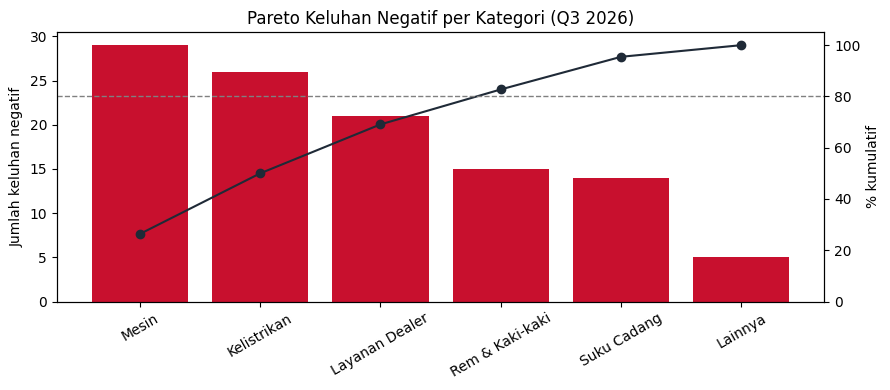

In [20]:
negatif = hasil[hasil["sentimen"] == "negatif"]

# (a) Tabel silang kategori × wilayah
pivot = pd.crosstab(negatif["kategori"], negatif["wilayah"], margins=True, margins_name="Total")
display(pivot.drop(index="Total").sort_values("Total", ascending=False))

# (b) Diagram Pareto: kategori mana yang menyumbang 80% keluhan?
pareto = negatif["kategori"].value_counts()
kumulatif = pareto.cumsum() / pareto.sum() * 100

fig, ax1 = plt.subplots()
ax1.bar(pareto.index, pareto.values, color="#C8102E")
ax1.set_ylabel("Jumlah keluhan negatif")
ax1.tick_params(axis="x", rotation=30)
ax2 = ax1.twinx()                                  # sumbu-Y kedua untuk persentase kumulatif
ax2.plot(pareto.index, kumulatif.values, color="#1F2A37", marker="o")
ax2.axhline(80, color="gray", linestyle="--", linewidth=1)
ax2.set_ylim(0, 105)
ax2.set_ylabel("% kumulatif")
ax1.set_title("Pareto Keluhan Negatif per Kategori (Q3 2026)")
plt.tight_layout()
plt.savefig("pareto_keluhan.png", dpi=150)
plt.show()

**Penjelasan kode**
- `pd.crosstab(baris, kolom, margins=True)` — tabel frekuensi dua dimensi; `margins=True` menambah baris & kolom **Total**. `drop(index="Total")` membuang baris total sebelum diurutkan agar kategori terbesar tampil paling atas.
- `value_counts()` — menghitung frekuensi tiap kategori, otomatis terurut dari yang terbesar — cocok untuk Pareto.
- `cumsum() / sum() * 100` — persentase kumulatif. Garis 80% membantu menerapkan prinsip Pareto (80/20): fokus perbaikan pada sedikit kategori yang menyumbang sebagian besar masalah.
- `ax1.twinx()` — membuat sumbu-Y kedua yang berbagi sumbu-X; batang = jumlah, garis = persentase.
- `plt.savefig(...)` sebelum `plt.show()` — menyimpan grafik ke file PNG untuk laporan.

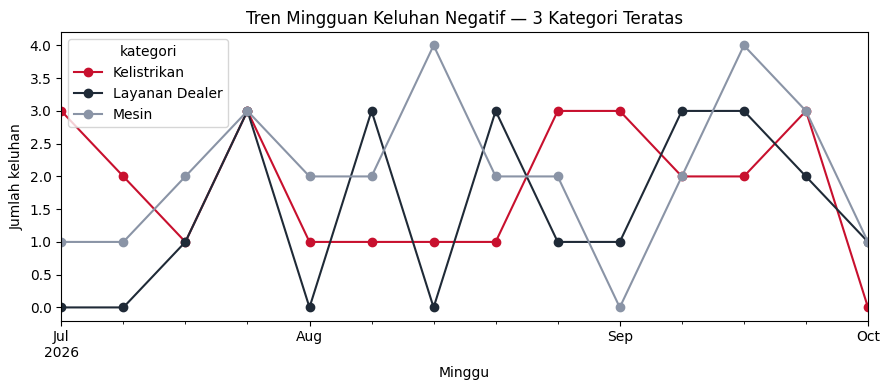

,model,komponen,jumlah
1,ADV 160,komunikasi mekanik,2
13,BeAT,starter,6
19,CBR150R,waktu tunggu,2
22,Genio,performa mesin,3
34,PCX 160,waktu tunggu,4
40,Scoopy,starter,3
43,Vario 125,ketersediaan part,10


In [21]:
# (c) Tren mingguan keluhan negatif untuk 3 kategori teratas
top3 = pareto.index[:3]
tren = (negatif[negatif["kategori"].isin(top3)]
        .groupby([pd.Grouper(key="tanggal", freq="W-MON"), "kategori"])
        .size()
        .unstack(fill_value=0))

ax = tren.plot(marker="o", color=["#C8102E", "#1F2A37", "#8A94A6"])
ax.set_title("Tren Mingguan Keluhan Negatif — 3 Kategori Teratas")
ax.set_xlabel("Minggu")
ax.set_ylabel("Jumlah keluhan")
plt.tight_layout()
plt.savefig("tren_keluhan.png", dpi=150)
plt.show()

# (d) Komponen terbanyak per model motor
top_komp_model = (negatif.groupby(["model", "komponen"]).size()
                  .rename("jumlah").reset_index()
                  .sort_values(["model", "jumlah"], ascending=[True, False])
                  .groupby("model").head(1))
top_komp_model

**Penjelasan kode**
- `isin(top3)` — menyaring baris yang kategorinya termasuk tiga teratas.
- `pd.Grouper(key="tanggal", freq="W-MON")` — mengelompokkan tanggal per minggu (minggu berakhir hari Senin). Ini cara ringkas melakukan *resampling* di dalam `groupby`.
- `.size().unstack(fill_value=0)` — menghitung jumlah baris per (minggu, kategori), lalu memindahkan kategori menjadi kolom; minggu tanpa kejadian diisi 0.
- `tren.plot(...)` — pandas memanggil matplotlib di belakang layar; setiap kolom menjadi satu garis.
- Blok (d): `groupby(["model","komponen"]).size()` menghitung kombinasi, `sort_values` mengurutkan jumlah terbesar per model, lalu `groupby("model").head(1)` mengambil **satu komponen teratas** di tiap model.

## Langkah 7 — Alat #5: Ringkasan eksekutif oleh LLM (berbasis fakta)
Pola penting: **Python menghitung fakta → fakta dikirim ke LLM → LLM menulis narasi.**
LLM tidak diberi data mentah, hanya ringkasan angka (lebih hemat token, lebih aman, dan mengurangi halusinasi).

In [22]:
urgen = hasil[hasil["urgensi"] == "tinggi"]
fakta = {
    "periode": "Juli–September 2026",
    "total_keluhan": int(len(hasil)),
    "persen_negatif": round(len(negatif) / len(hasil) * 100, 1),
    "top_kategori_negatif": [{"kategori": k, "jumlah": int(v)} for k, v in pareto.head(3).items()],
    "jumlah_urgensi_tinggi": int(len(urgen)),
    "wilayah_urgensi_tinggi_terbanyak": urgen["wilayah"].value_counts().idxmax(),
    "model_keluhan_terbanyak": negatif["model"].value_counts().idxmax(),
}

PROMPT_RINGKASAN = f"""TUGAS: RINGKASAN_EKSEKUTIF
Tulis ringkasan eksekutif (maks. 120 kata) untuk manajemen, dalam bahasa Indonesia formal.
Gunakan HANYA angka pada FAKTA. Jangan menambah angka baru. Akhiri dengan 3 rekomendasi tindak lanjut.

FAKTA:
{json.dumps(fakta, ensure_ascii=False, indent=2)}
AKHIR_FAKTA"""

ringkasan = llm.generate(PROMPT_RINGKASAN)
print(json.dumps(fakta, ensure_ascii=False, indent=2))
print("\n" + "=" * 70 + "\n")
print(ringkasan)

{
  "periode": "Juli–September 2026",
  "total_keluhan": 120,
  "persen_negatif": 91.7,
  "top_kategori_negatif": [
    {
      "kategori": "Mesin",
      "jumlah": 29
    },
    {
      "kategori": "Kelistrikan",
      "jumlah": 26
    },
    {
      "kategori": "Layanan Dealer",
      "jumlah": 21
    }
  ],
  "jumlah_urgensi_tinggi": 37,
  "wilayah_urgensi_tinggi_terbanyak": "Jabodetabek",
  "model_keluhan_terbanyak": "BeAT"
}


**Ringkasan Eksekutif — Keluhan Pelanggan Juli–September 2026**

Tercatat 120 masukan pelanggan, 91.7% di antaranya bernada negatif. Kategori keluhan terbanyak adalah Mesin (29 kasus) diikuti Kelistrikan (26 kasus). Terdapat 37 keluhan berurgensi tinggi yang terkait keselamatan/berhentinya kendaraan, terkonsentrasi di wilayah Jabodetabek.

**Rekomendasi:** (1) Tim Quality menelusuri akar masalah mesin pada model BeAT; (2) After Sales meninjau kapasitas bengkel dan ketersediaan part; (3) Keluhan urgensi tinggi ditindaklanjuti maksimal 2x24 jam.


**Penjelasan kode**
- `int(...)` pada setiap angka — nilai NumPy (`np.int64`) tidak bisa langsung diubah ke JSON; konversi ke `int` Python mencegah error `TypeError: Object of type int64 is not JSON serializable`.
- `value_counts().idxmax()` — mengambil **label** dengan frekuensi tertinggi (bukan angkanya).
- `f"""..."""` — *f-string* multi-baris; `{json.dumps(fakta, indent=2)}` menyisipkan fakta sebagai JSON rapi.
- Instruksi "Gunakan HANYA angka pada FAKTA" adalah teknik **grounding** — mengikat jawaban AI pada data yang sudah diverifikasi. (Materi 4 akan menambahkan pengecekan angka otomatis.)

## Langkah 8 — Alat #6: Router / Agent sederhana (*tool calling*)
Pengguna sering bertanya ad-hoc: *"Berapa keluhan kelistrikan di Jawa Barat?"*. Daripada menulis kode baru setiap kali, kita sediakan beberapa **tools** (fungsi Python) dan biarkan LLM **memilih tool beserta argumennya** dalam format JSON. Python yang mengeksekusi tool, lalu LLM merangkai jawaban.

```
Pertanyaan ─► LLM (pilih tool + argumen, JSON) ─► Python menjalankan tool ─► LLM menyusun jawaban
```

In [23]:
# ---------- Definisi tools (fungsi Python biasa) ----------
def hitung_keluhan(kategori=None, wilayah=None):
    d = hasil[hasil["sentimen"] == "negatif"]
    if kategori:
        d = d[d["kategori"] == kategori]
    if wilayah:
        d = d[d["wilayah"] == wilayah]
    return {"jumlah_keluhan_negatif": int(len(d)), "kategori": kategori or "semua", "wilayah": wilayah or "semua"}


def top_komponen(model=None, n=3):
    d = hasil[hasil["sentimen"] == "negatif"]
    if model:
        d = d[d["model"] == model]
    return {"model": model or "semua", "top_komponen": d["komponen"].value_counts().head(n).to_dict()}


def cari_contoh(kata_kunci, n=3):
    d = hasil[hasil["teks"].str.lower().str.contains(kata_kunci.lower(), regex=False)
              | hasil["kategori"].str.lower().str.contains(kata_kunci.lower(), regex=False)]
    return {"kata_kunci": kata_kunci, "contoh": d["teks"].drop_duplicates().head(n).tolist()}


TOOLS = {"hitung_keluhan": hitung_keluhan, "top_komponen": top_komponen, "cari_contoh": cari_contoh}

DESKRIPSI_TOOLS = """
1. hitung_keluhan(kategori, wilayah) → jumlah keluhan negatif. Argumen boleh null.
2. top_komponen(model, n) → komponen paling sering dikeluhkan, opsional per model motor.
3. cari_contoh(kata_kunci, n) → contoh teks keluhan yang mengandung kata kunci.
"""


def tanya_agent(pertanyaan):
    # 1) LLM memilih tool
    prompt_pilih = f"""TUGAS: PILIH_TOOL
Anda adalah router. Pilih SATU tool yang paling tepat untuk menjawab pertanyaan.
Tools tersedia:{DESKRIPSI_TOOLS}
Nilai kategori valid: {KATEGORI_VALID}. Wilayah valid: {WILAYAH}. Model valid: {MODEL_MOTOR}.
Jawab HANYA JSON: {{"tool": "<nama>", "args": {{...}}}}
PERTANYAAN: {pertanyaan} AKHIR_PERTANYAAN"""
    keputusan = ambil_json(llm.generate(prompt_pilih))

    # 2) Python memeriksa & menjalankan tool (LLM tidak pernah menjalankan kode sendiri)
    nama = keputusan.get("tool")
    if nama not in TOOLS:
        return f"Tool '{nama}' tidak dikenal — pertanyaan diteruskan ke analis."
    hasil_tool = TOOLS[nama](**keputusan.get("args", {}))

    # 3) LLM merangkai jawaban dari hasil tool
    prompt_jawab = f"""TUGAS: JAWAB_PERTANYAAN
Jawab pertanyaan pengguna secara singkat HANYA berdasarkan HASIL_TOOL.
PERTANYAAN: {pertanyaan} AKHIR_PERTANYAAN
HASIL_TOOL: {json.dumps(hasil_tool, ensure_ascii=False)} AKHIR_HASIL"""
    print(f"[router] tool={nama} args={keputusan.get('args')}")
    return llm.generate(prompt_jawab)


for q in ["Berapa keluhan Kelistrikan di Jabodetabek?",
          "Komponen apa yang paling sering dikeluhkan pada BeAT?",
          "Tunjukkan contoh keluhan tentang antrian"]:
    print("Q:", q)
    print("A:", tanya_agent(q), "\n")

Q: Berapa keluhan Kelistrikan di Jabodetabek?
[router] tool=hitung_keluhan args={'kategori': 'Kelistrikan', 'wilayah': 'Jabodetabek'}
A: Terdapat 10 keluhan negatif untuk kategori Kelistrikan di wilayah Jabodetabek pada periode data. 

Q: Komponen apa yang paling sering dikeluhkan pada BeAT?
[router] tool=top_komponen args={'model': 'BeAT', 'n': 3}
A: Komponen yang paling sering dikeluhkan pada model BeAT: starter (6 kasus), waktu tunggu (5 kasus), sistem bahan bakar/idle (5 kasus). 

Q: Tunjukkan contoh keluhan tentang antrian
[router] tool=cari_contoh args={'kata_kunci': 'antrian', 'n': 3}
A: Contoh keluhan: Antrian servis di dealer lama sekali, lebih dari 3 jam 



**Penjelasan kode**
- **Tools** adalah fungsi Python biasa yang menghasilkan dict. Mengembalikan dict (bukan teks) membuat hasil mudah diubah ke JSON untuk LLM.
- `str.contains(kata, regex=False)` — pencarian teks sederhana; `regex=False` agar karakter khusus (mis. `?`) tidak dianggap pola regex.
- `drop_duplicates()` — membuang teks yang sama persis agar contoh yang ditampilkan beragam.
- `TOOLS = {...}` — "daftar putih" (*whitelist*) fungsi yang boleh dipanggil. LLM hanya memberikan **nama** tool; Python yang memutuskan apakah nama itu sah.
- `{{"tool": ...}}` — kurung kurawal ganda di dalam f-string agar tercetak sebagai `{` literal, bukan placeholder.
- `TOOLS[nama](**keputusan.get("args", {}))` — memanggil fungsi berdasarkan nama, dan `**` membuka dict argumen menjadi argumen bernama (`kategori="Kelistrikan", wilayah="Jawa Barat"`).
- Pola 3 langkah (pilih → jalankan → jawab) adalah inti dari **agent / function calling** pada platform LLM modern. Keamanannya terletak pada fakta bahwa **LLM tidak menjalankan kode apa pun**; ia hanya mengusulkan.

## Langkah 9 — Orkestrator: menyatukan semua alat dalam satu fungsi
Langkah-langkah di atas kita bungkus menjadi `jalankan_pipeline()` — satu tombol untuk menjalankan seluruh proses, lengkap dengan pencatatan waktu tiap langkah dan penyimpanan hasil. Fungsi seperti inilah yang nantinya dijadwalkan (mis. tiap Senin pagi) dengan *scheduler*.

In [24]:
import os

def jalankan_pipeline(df_input, folder="output_nb01"):
    os.makedirs(folder, exist_ok=True)
    jejak = []

    def catat(langkah, t0, info=""):
        jejak.append({"langkah": langkah, "durasi_detik": round(time.time() - t0, 3), "info": info})

    # 1-2) Ekstraksi + validasi
    t0 = time.time()
    rows = []
    for _, r in df_input.iterrows():
        h, masalah = validasi(ekstrak_feedback(r["teks"]))
        rows.append({**r.to_dict(), **h, "perlu_review": bool(masalah), "catatan_validasi": "; ".join(masalah)})
    data = pd.DataFrame(rows)
    catat("ekstraksi+validasi", t0, f"{len(data)} baris, {data['perlu_review'].sum()} perlu review")

    # 3) Antrean review manusia (disimpan; pipeline lanjut dengan data yang lolos)
    t0 = time.time()
    data[data["perlu_review"]].to_csv(f"{folder}/antrean_review.csv", index=False)
    siap = data[~data["perlu_review"]]
    catat("antrean_review", t0, f"{len(data) - len(siap)} baris menunggu reviewer")

    # 4) Analisis
    t0 = time.time()
    neg = siap[siap["sentimen"] == "negatif"]
    ringkas = neg.groupby(["kategori", "wilayah"]).size().rename("jumlah").reset_index()
    ringkas.to_csv(f"{folder}/ringkasan_kategori_wilayah.csv", index=False)
    catat("analisis", t0, f"{len(neg)} keluhan negatif")

    # 5) Narasi
    t0 = time.time()
    p = neg["kategori"].value_counts()
    u = siap[siap["urgensi"] == "tinggi"]
    fakta_p = {"periode": "Juli–September 2026", "total_keluhan": int(len(siap)),
               "persen_negatif": round(len(neg) / max(len(siap), 1) * 100, 1),
               "top_kategori_negatif": [{"kategori": k, "jumlah": int(v)} for k, v in p.head(3).items()],
               "jumlah_urgensi_tinggi": int(len(u)),
               "wilayah_urgensi_tinggi_terbanyak": u["wilayah"].value_counts().idxmax(),
               "model_keluhan_terbanyak": neg["model"].value_counts().idxmax()}
    narasi = llm.generate(PROMPT_RINGKASAN.split("FAKTA:")[0]
                          + "FAKTA:\n" + json.dumps(fakta_p, ensure_ascii=False) + "\nAKHIR_FAKTA")
    with open(f"{folder}/ringkasan_eksekutif.md", "w", encoding="utf-8") as f:
        f.write(narasi)
    catat("narasi", t0)

    pd.DataFrame(jejak).to_csv(f"{folder}/log_pipeline.csv", index=False)
    return pd.DataFrame(jejak)


log_pipeline = jalankan_pipeline(df_keluhan)
display(log_pipeline)
print("File yang dihasilkan:", sorted(os.listdir("output_nb01")))
print("\nLog panggilan LLM (5 terakhir):")
pd.DataFrame(llm.log).tail(5)

,langkah,durasi_detik,info
0,ekstraksi+validasi,0.037,"120 baris, 26 perlu review"
1,antrean_review,0.003,26 baris menunggu reviewer
2,analisis,0.014,84 keluhan negatif
3,narasi,0.006,


File yang dihasilkan: ['antrean_review.csv', 'log_pipeline.csv', 'ringkasan_eksekutif.md', 'ringkasan_kategori_wilayah.csv']

Log panggilan LLM (5 terakhir):


,waktu,mode,panjang_prompt,panjang_jawaban,durasi_detik
245,2026-10-09 19:16:40,simulasi,757,154,0.0
246,2026-10-09 19:16:40,simulasi,771,164,0.0
247,2026-10-09 19:16:40,simulasi,768,159,0.0
248,2026-10-09 19:16:40,simulasi,775,128,0.0
249,2026-10-09 19:16:40,simulasi,584,548,0.0


**Penjelasan kode**
- `os.makedirs(folder, exist_ok=True)` — membuat folder output; `exist_ok=True` agar tidak error jika folder sudah ada.
- Fungsi dalam fungsi `catat()` — *closure* yang menambah catatan ke list `jejak` milik fungsi luar. Setiap langkah mencatat durasi dan informasi ringkas.
- Pipeline **tidak berhenti** karena baris bermasalah: baris tersebut disimpan ke antrean review, sementara analisis berjalan dengan data yang sudah lolos. Pola ini disebut *graceful degradation*.
- `max(len(siap), 1)` — mencegah pembagian dengan nol bila semua baris masuk review.
- `PROMPT_RINGKASAN.split("FAKTA:")[0]` — memakai ulang bagian instruksi dari prompt sebelumnya lalu menempelkan fakta baru; satu template, banyak pemakaian.
- `llm.log` — log dari `LLMClient` (jumlah panggilan, durasi, panjang prompt). Di lingkungan produksi, log ini dipakai untuk memantau **biaya token** dan **latensi**.

## Ringkasan
| Alat | Peran dalam solusi | Siapa yang "unggul" |
|---|---|---|
| LLM — ekstraksi | Mengubah teks bebas → JSON terstruktur | AI (bahasa) |
| Validator Python | Memastikan kontrak data dipatuhi | Aturan pasti |
| Reviewer | Menangani kasus ragu & salah label | Manusia (penilaian) |
| pandas + matplotlib | Menghitung Pareto, tren, tabel silang | Python (angka) |
| LLM — narasi | Menulis ringkasan berbasis fakta | AI (bahasa) |
| Router/agent | Menjawab pertanyaan ad-hoc dengan tools | AI + Python |
| Orkestrator | Menjalankan semuanya, mencatat log | Power User (desain) |

## Latihan
1. Tambahkan kategori baru **"Aksesori"** ke `KATEGORI_VALID` dan aturan simulator, lalu jalankan ulang. Apa yang terjadi pada antrean review?
2. Ubah `AMBANG_CONFIDENCE` menjadi 0,85. Berapa baris yang kini perlu review? Diskusikan *trade-off* antara otomasi dan akurasi.
3. Tambahkan tool keempat `tren_mingguan(kategori)` ke router dan uji dengan pertanyaan baru.
4. (Jika punya API key) Jalankan notebook dengan `LLM_MODE=anthropic` dan bandingkan hasil ekstraksi LLM sungguhan dengan simulator.